In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 2 — Challenge A: Cybersecurity

**Machine Learning — 2026/2027**

This notebook contains the complete Challenge A route required in Practice 2. The team-generated folds are constructed and frozen first; after P2.2(f), all scored development results use the course-owned canonical assignment.

In [2]:
from pathlib import Path
import json
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    brier_score_loss,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

PROJECT_DIR = Path(".")
CYBER_DIR = PROJECT_DIR / "datos" / "cyber"
FOLDS_DIR = PROJECT_DIR / "folds"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

CYBER_DEVELOPMENT_FILE = CYBER_DIR / "cyber_development.csv"
CYBER_GROUPS_FILE = CYBER_DIR / "cyber_groups.csv"
CYBER_CLASS_CODES_FILE = CYBER_DIR / "cyber_class_codes.json"
CYBER_CANONICAL_FOLDS_FILE = FOLDS_DIR / "cyber_folds.csv"
VALIDATOR_FILE = PROJECT_DIR / "herramientas" / "validate_submission.py"

## P2.1 — Data contract and exploration

We load the fixed development table and group sidecar, verify the schema explicitly, report every class support, name ransomware's support, and count the distinct exact feature groups. `feature_group` is split metadata only and is never passed to the estimator as a predictor.

In [3]:
cyber = pd.read_csv(CYBER_DEVELOPMENT_FILE)
cyber_groups = pd.read_csv(CYBER_GROUPS_FILE)

with open(CYBER_CLASS_CODES_FILE, "r", encoding="utf-8") as f:
    class_codes = {int(code): name for code, name in json.load(f).items()}

NOMINAL_FEATURES = ["proto", "service", "conn_state"]
NUMERIC_FEATURES = [
    "duration", "src_bytes", "dst_bytes", "missed_bytes",
    "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes",
]
MODEL_FEATURES = NOMINAL_FEATURES + NUMERIC_FEATURES

EXPECTED_DEVELOPMENT_COLUMNS = ["row_id"] + MODEL_FEATURES + ["attack_code"]
EXPECTED_GROUP_COLUMNS = ["row_id", "feature_group"]

assert list(cyber.columns) == EXPECTED_DEVELOPMENT_COLUMNS
assert list(cyber_groups.columns) == EXPECTED_GROUP_COLUMNS
assert cyber["row_id"].is_unique
assert cyber_groups["row_id"].is_unique
assert set(cyber["row_id"]) == set(cyber_groups["row_id"])

print("Development shape:", cyber.shape)
print("Development columns:")
print(list(cyber.columns))
print()
print("Group metadata shape:", cyber_groups.shape)

Development shape: (34928, 13)
Development columns:
['row_id', 'proto', 'service', 'conn_state', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'attack_code']

Group metadata shape: (34928, 2)


In [4]:
class_support = (
    cyber["attack_code"].value_counts().sort_index().rename("support").to_frame()
)
class_support["class_name"] = class_support.index.map(class_codes)
class_support = class_support[["class_name", "support"]]
display(class_support)

ransomware_code = next(code for code, name in class_codes.items() if name == "ransomware")
ransomware_support = int(class_support.loc[ransomware_code, "support"])
n_feature_groups = int(cyber_groups["feature_group"].nunique())

print("Ransomware support:", ransomware_support)
print("Distinct feature_group values:", n_feature_groups)

,class_name,support
attack_code,,
0,backdoor,1573
1,ddos,4800
2,dos,4800
3,injection,4800
4,mitm,805
5,normal,4800
6,password,4800
7,ransomware,208
8,scanning,3542


Ransomware support: 208
Distinct feature_group values: 34883


### P2.1 result

The cybersecurity development set contains 34,928 observations and 11 model features. The ten class supports are reported above. Ransomware is the rarest class, with 208 observations. The group sidecar contains 34,883 distinct `feature_group` values, so some rows share an exact feature vector and must be kept together by the grouped protocol.

## P2.2(a) — Construct our grouped five-fold protocol

For Challenge A the required construction is a five-fold `StratifiedGroupKFold`: stratification uses `attack_code`, grouping uses `feature_group`, and the fixed project seed is consumed by the shuffled grouped splitter.

In [5]:
cyber_all = cyber.merge(cyber_groups, on="row_id", how="left", validate="one_to_one")
X_cyber = cyber_all[MODEL_FEATURES]
y_cyber = cyber_all["attack_code"]
groups_cyber = cyber_all["feature_group"]

cv_grouped = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=PROJECT_RANDOM_STATE,
)

own_fold_id = np.empty(len(cyber_all), dtype=int)
fold_sizes = []

for q, (train_idx, valid_idx) in enumerate(
    cv_grouped.split(X_cyber, y_cyber, groups=groups_cyber),
    start=1,
):
    own_fold_id[valid_idx] = q
    fold_sizes.append({
        "fold": q,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
    })

own_cyber_folds = pd.DataFrame({
    "row_id": cyber_all["row_id"],
    "fold_id": own_fold_id,
})

display(pd.DataFrame(fold_sizes))
display(own_cyber_folds.head())

,fold,train_rows,validation_rows
0,1,27942,6986
1,2,27942,6986
2,3,27943,6985
3,4,27942,6986
4,5,27943,6985


,row_id,fold_id
0,C00000,2
1,C00001,1
2,C00002,3
3,C00003,2
4,C00004,1


## P2.2(b) — Verify the grouping invariant and contrast row-wise CV

The invariant is that no exact `feature_group` may appear in both the training and validation portions of the same fold. We verify it for every grouped fold, then inspect an ordinary row-wise `StratifiedKFold` to show what the grouping constraint prevents.

In [6]:
grouped_invariant_rows = []

for q, (train_idx, valid_idx) in enumerate(
    cv_grouped.split(X_cyber, y_cyber, groups=groups_cyber),
    start=1,
):
    train_groups = set(groups_cyber.iloc[train_idx])
    valid_groups = set(groups_cyber.iloc[valid_idx])
    overlap = train_groups.intersection(valid_groups)
    grouped_invariant_rows.append({
        "fold": q,
        "shared_feature_groups": len(overlap),
        "invariant_holds": len(overlap) == 0,
    })

grouped_invariant_report = pd.DataFrame(grouped_invariant_rows)
display(grouped_invariant_report)
assert grouped_invariant_report["invariant_holds"].all()

cv_rowwise = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=PROJECT_RANDOM_STATE,
)
rowwise_overlap_rows = []

for q, (train_idx, valid_idx) in enumerate(cv_rowwise.split(X_cyber, y_cyber), start=1):
    train_groups = set(groups_cyber.iloc[train_idx])
    valid_groups = set(groups_cyber.iloc[valid_idx])
    overlap = train_groups.intersection(valid_groups)
    rowwise_overlap_rows.append({
        "fold": q,
        "shared_feature_groups": len(overlap),
    })

rowwise_overlap_report = pd.DataFrame(rowwise_overlap_rows)
display(rowwise_overlap_report)

,fold,shared_feature_groups,invariant_holds
0,1,0,True
1,2,0,True
2,3,0,True
3,4,0,True
4,5,0,True


,fold,shared_feature_groups
0,1,13
1,2,13
2,3,14
3,4,10
4,5,15


### P2.2(b) interpretation

The grouped construction satisfies the invariant in all five folds: every reported overlap is zero. Ordinary row-wise stratification has no knowledge of `feature_group`, so identical feature groups can be split across training and validation. The row-wise overlap table demonstrates that this occurs here.

## P2.2(d) — Grouped versus row-wise evaluation

The course fixes this demonstration pipeline so that only the splitting protocol varies: `KNeighborsClassifier(n_neighbors=5)`, one-hot encoding on the three nominal predictors, `log1p` followed by standardisation on the eight numeric predictors, and macro F1 as the metric. This is a protocol demonstration, not model selection.

In [7]:
def make_cyber_pipeline(n_neighbors):
    numeric_preprocessing = Pipeline([
        ("log1p", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
    ])
    preprocessing = ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore"), NOMINAL_FEATURES),
        ("numeric", numeric_preprocessing, NUMERIC_FEATURES),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("knn", KNeighborsClassifier(n_neighbors=n_neighbors)),
    ])

cyber_comparison_pipeline = make_cyber_pipeline(5)

grouped_scores = cross_validate(
    cyber_comparison_pipeline,
    X_cyber,
    y_cyber,
    groups=groups_cyber,
    cv=cv_grouped,
    scoring="f1_macro",
    n_jobs=1,
)["test_score"]

rowwise_scores = cross_validate(
    cyber_comparison_pipeline,
    X_cyber,
    y_cyber,
    cv=cv_rowwise,
    scoring="f1_macro",
    n_jobs=1,
)["test_score"]

comparison_scores = pd.DataFrame({
    "fold": np.arange(1, 6),
    "grouped_macro_f1": grouped_scores,
    "rowwise_macro_f1": rowwise_scores,
})
display(comparison_scores.round(4))

grouped_mean = float(grouped_scores.mean())
rowwise_mean = float(rowwise_scores.mean())
observed_difference = rowwise_mean - grouped_mean

print(f"Grouped mean macro F1 : {grouped_mean:.4f}")
print(f"Row-wise mean macro F1: {rowwise_mean:.4f}")
print(f"Row-wise - grouped     : {observed_difference:+.4f}")

,fold,grouped_macro_f1,rowwise_macro_f1
0,1,0.9419,0.9372
1,2,0.9466,0.9404
2,3,0.9516,0.9476
3,4,0.9399,0.9536
4,5,0.9408,0.9424


Grouped mean macro F1 : 0.9442
Row-wise mean macro F1: 0.9443
Row-wise - grouped     : +0.0001


### P2.2(d) interpretation

The two mean macro-F1 estimates are almost identical in this run, with the row-wise estimate only slightly higher. The statement does not predict the sign or size of the Challenge A difference; the value above is therefore reported as an empirical result rather than interpreted as evidence that row-wise validation is preferable.

## P2.2(e) — Why splitting identical feature groups is methodologically undesirable

The methodological argument does not depend on the observed gap. If an exact `feature_group` is allowed on both sides of a fold, the validation portion can contain an observation with the same predictor vector as an observation already available for fitting. The resulting score no longer estimates generalisation to a different exact feature group. Grouping is therefore required because of what the score is intended to estimate, even when the numerical gap happens to be small.

## P2.2(f) — Freeze our construction and compare with the canonical folds

Our construction and invariant report above are now frozen. We next read the released course-owned `cyber_folds.csv` and compare the assignments without altering our earlier construction.

In [8]:
canonical_folds = pd.read_csv(CYBER_CANONICAL_FOLDS_FILE)
assert list(canonical_folds.columns) == ["row_id", "fold_id"]
assert canonical_folds["row_id"].is_unique
assert set(canonical_folds["row_id"]) == set(own_cyber_folds["row_id"])
assert set(canonical_folds["fold_id"]) == {0, 1, 2, 3, 4}

fold_comparison = own_cyber_folds.merge(
    canonical_folds,
    on="row_id",
    how="inner",
    suffixes=("_ours", "_canonical"),
    validate="one_to_one",
)

display(pd.crosstab(
    fold_comparison["fold_id_ours"],
    fold_comparison["fold_id_canonical"],
    rownames=["our fold id"],
    colnames=["canonical fold id"],
))

same_after_label_normalisation = (
    fold_comparison["fold_id_ours"] - 1
    == fold_comparison["fold_id_canonical"]
)

print("Exact agreement using the raw numeric labels:", f"{(fold_comparison['fold_id_ours'] == fold_comparison['fold_id_canonical']).mean():.4f}")
print("Agreement after converting our 1..5 labels to 0..4:", f"{same_after_label_normalisation.mean():.4f}")
assert same_after_label_normalisation.all()

canonical fold id,0,1,2,3,4
our fold id,,,,,
1,6986,0,0,0,0
2,0,6986,0,0,0
3,0,0,6985,0,0
4,0,0,0,6986,0
5,0,0,0,0,6985


Exact agreement using the raw numeric labels: 0.0000
Agreement after converting our 1..5 labels to 0..4: 1.0000


### P2.2(f) interpretation

The partitions are identical. The only discrepancy is the fold-label convention: our construction numbered validation folds 1–5, while the canonical sidecar numbers them 0–4. After subtracting one from our labels, every row has exactly the canonical assignment. No row changes partition membership.

## P2.2(g) — Adopt the canonical assignment

From this point onward the team-generated splitter is no longer the project authority. Every scored development result below uses the released canonical `fold_id` assignment.

In [9]:
canonical_folds = cyber[["row_id"]].merge(
    canonical_folds,
    on="row_id",
    how="left",
    validate="one_to_one",
)
canonical_fold_id = canonical_folds["fold_id"].to_numpy()
CANONICAL_FOLD_VALUES = sorted(canonical_folds["fold_id"].unique())

canonical_cv = []
canonical_check_rows = []
for fold_id in CANONICAL_FOLD_VALUES:
    valid_idx = np.flatnonzero(canonical_fold_id == fold_id)
    train_idx = np.flatnonzero(canonical_fold_id != fold_id)
    canonical_cv.append((train_idx, valid_idx))

    train_groups = set(groups_cyber.iloc[train_idx])
    valid_groups = set(groups_cyber.iloc[valid_idx])
    valid_classes = set(y_cyber.iloc[valid_idx])
    canonical_check_rows.append({
        "fold_id": fold_id,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
        "shared_feature_groups": len(train_groups.intersection(valid_groups)),
        "validation_classes": len(valid_classes),
    })

canonical_check_report = pd.DataFrame(canonical_check_rows)
display(canonical_check_report)
assert (canonical_check_report["shared_feature_groups"] == 0).all()
assert (canonical_check_report["validation_classes"] == len(class_codes)).all()

,fold_id,train_rows,validation_rows,shared_feature_groups,validation_classes
0,0,27942,6986,0,10
1,1,27942,6986,0,10
2,2,27943,6985,0,10
3,3,27942,6986,0,10
4,4,27943,6985,0,10


## P2.4 — Baseline and nearest neighbours on the canonical folds

The classification baseline is `DummyClassifier(strategy="most_frequent")`. For KNN we use the compact predeclared neighbour grid used in the Unit 5 model-selection notebook: `[1, 3, 5, 7, 9, 11, 15, 21, 31]`. The selection metric is the course-primary macro F1.

**Scaling decision.** KNN is distance-based, so feature scale changes neighbourhoods. The three nominal predictors are one-hot encoded. The eight non-negative numeric predictors span very different ranges, so the frozen Cyber representation applies `log1p` and then standardisation. Both fitted transformations remain inside the pipeline and are therefore fitted separately on each training fold.

In [10]:
N_NEIGHBOURS_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]

# Baseline, evaluated on exactly the canonical folds.
dummy_fold_rows = []
for fold_id, (train_idx, valid_idx) in zip(CANONICAL_FOLD_VALUES, canonical_cv):
    model = DummyClassifier(strategy="most_frequent")
    start = time.perf_counter()
    model.fit(X_cyber.iloc[train_idx], y_cyber.iloc[train_idx])
    fit_time = time.perf_counter() - start
    pred = model.predict(X_cyber.iloc[valid_idx])
    y_valid = y_cyber.iloc[valid_idx]
    dummy_fold_rows.append({
        "fold_id": fold_id,
        "macro_f1": f1_score(y_valid, pred, average="macro"),
        "weighted_f1": f1_score(y_valid, pred, average="weighted"),
        "accuracy": accuracy_score(y_valid, pred),
        "fit_time_s": fit_time,
    })

dummy_metrics = pd.DataFrame(dummy_fold_rows)
display(dummy_metrics.round(6))
print("Dummy mean macro F1:", f"{dummy_metrics['macro_f1'].mean():.6f}")

# Whole K_NN curve: the same canonical folds are reused for every candidate.
knn_curve_rows = []
knn_fold_scores = {}
for n_neighbours in N_NEIGHBOURS_GRID:
    result = cross_validate(
        make_cyber_pipeline(n_neighbours),
        X_cyber,
        y_cyber,
        cv=canonical_cv,
        scoring="f1_macro",
        n_jobs=1,
    )
    fold_scores = result["test_score"]
    knn_fold_scores[n_neighbours] = fold_scores
    knn_curve_rows.append({
        "K_NN": n_neighbours,
        "mean_macro_f1": fold_scores.mean(),
        "sd_across_folds": fold_scores.std(ddof=0),
        "range_across_folds": fold_scores.max() - fold_scores.min(),
        "min_fold": fold_scores.min(),
        "max_fold": fold_scores.max(),
    })

knn_curve = pd.DataFrame(knn_curve_rows)
display(knn_curve.round(6))

best_index = knn_curve["mean_macro_f1"].idxmax()
selected_neighbours = int(knn_curve.loc[best_index, "K_NN"])
print("Selected K_NN:", selected_neighbours)
print("Best mean canonical macro F1:", f"{knn_curve.loc[best_index, 'mean_macro_f1']:.6f}")

,fold_id,macro_f1,weighted_f1,accuracy,fit_time_s
0,0,0.024163,0.033204,0.137418,0.004574
1,1,0.024163,0.033204,0.137418,0.006481
2,2,0.024166,0.033213,0.137437,0.003985
3,3,0.024163,0.033204,0.137418,0.004117
4,4,0.024166,0.033213,0.137437,0.003457


Dummy mean macro F1: 0.024164


,K_NN,mean_macro_f1,sd_across_folds,range_across_folds,min_fold,max_fold
0,1,0.943712,0.003010,0.009338,0.939725,0.949063
1,3,0.945557,0.002295,0.006154,0.942843,0.948997
2,5,0.944165,0.004387,0.011749,0.939892,0.951641
3,7,0.943592,0.003893,0.011808,0.938347,0.950155
4,9,0.941254,0.004419,0.013003,0.934959,0.947961
5,11,0.939715,0.004212,0.011898,0.933060,0.944958
6,15,0.938469,0.003897,0.010681,0.933319,0.944000
7,21,0.928841,0.005123,0.014307,0.921409,0.935716
8,31,0.921483,0.005141,0.015261,0.913066,0.928326


Selected K_NN: 3
Best mean canonical macro F1: 0.945557


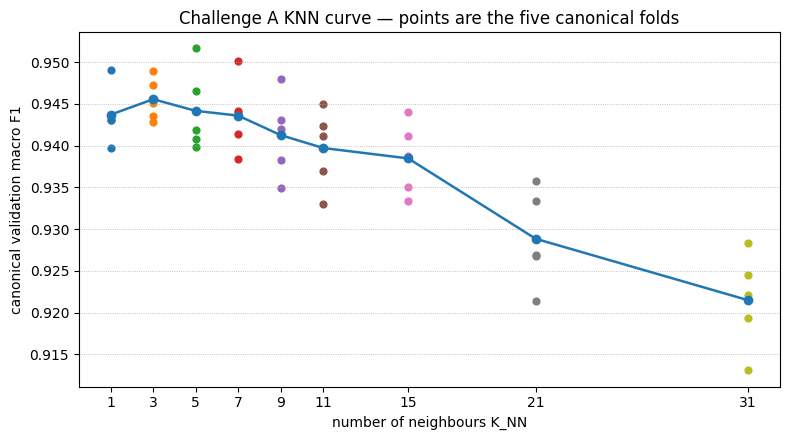

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for n_neighbours, fold_scores in knn_fold_scores.items():
    ax.scatter([n_neighbours] * len(fold_scores), fold_scores, s=24)
ax.plot(knn_curve["K_NN"], knn_curve["mean_macro_f1"], marker="o", linewidth=1.8)
ax.set_xticks(N_NEIGHBOURS_GRID)
ax.set_xlabel("number of neighbours K_NN")
ax.set_ylabel("canonical validation macro F1")
ax.set_title("Challenge A KNN curve — points are the five canonical folds")
ax.grid(axis="y", linestyle=":", linewidth=0.6)
plt.tight_layout()
plt.show()

In [12]:
# Refit the selected pipeline separately inside every canonical training fold.
# These out-of-fold predictions provide the supporting metrics and diagnostics.
n_rows = len(cyber)
class_values = sorted(class_codes)
oof_prediction = np.empty(n_rows, dtype=int)
oof_probability = np.zeros((n_rows, len(class_values)), dtype=float)
selected_fold_rows = []

for fold_id, (train_idx, valid_idx) in zip(CANONICAL_FOLD_VALUES, canonical_cv):
    model = make_cyber_pipeline(selected_neighbours)
    start = time.perf_counter()
    model.fit(X_cyber.iloc[train_idx], y_cyber.iloc[train_idx])
    fit_time = time.perf_counter() - start

    pred = model.predict(X_cyber.iloc[valid_idx])
    proba = model.predict_proba(X_cyber.iloc[valid_idx])
    oof_prediction[valid_idx] = pred

    # The class columns are mapped explicitly to the declared attack codes.
    for column, class_code in enumerate(model.named_steps["knn"].classes_):
        oof_probability[valid_idx, int(class_code)] = proba[:, column]

    y_valid = y_cyber.iloc[valid_idx]
    selected_fold_rows.append({
        "fold_id": fold_id,
        "macro_f1": f1_score(y_valid, pred, average="macro"),
        "weighted_f1": f1_score(y_valid, pred, average="weighted"),
        "accuracy": accuracy_score(y_valid, pred),
        "fit_time_s": fit_time,
    })

selected_metrics = pd.DataFrame(selected_fold_rows)
display(selected_metrics.round(6))
print("Mean macro F1   :", f"{selected_metrics['macro_f1'].mean():.6f}")
print("Mean weighted F1:", f"{selected_metrics['weighted_f1'].mean():.6f}")
print("Mean accuracy   :", f"{selected_metrics['accuracy'].mean():.6f}")

,fold_id,macro_f1,weighted_f1,accuracy,fit_time_s
0,0,0.943582,0.961904,0.961638,0.115662
1,1,0.947290,0.963697,0.963212,0.101549
2,2,0.948997,0.964503,0.964495,0.096635
3,3,0.942843,0.959209,0.959061,0.105826
4,4,0.945072,0.962428,0.961918,0.103873


Mean macro F1   : 0.945557
Mean weighted F1: 0.962348
Mean accuracy   : 0.962065


In [13]:
confusion = confusion_matrix(y_cyber, oof_prediction, labels=class_values)
class_names = [class_codes[c] for c in class_values]
confusion_frame = pd.DataFrame(confusion, index=class_names, columns=class_names)
display(confusion_frame)

per_class_rows = []
for position, class_code in enumerate(class_values):
    tp = int(confusion[position, position])
    fp = int(confusion[:, position].sum() - tp)
    fn = int(confusion[position, :].sum() - tp)
    support = int(confusion[position, :].sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    class_f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    per_class_rows.append({
        "attack_code": class_code,
        "class_name": class_codes[class_code],
        "support": support,
        "precision": precision,
        "recall": recall,
        "f1": class_f1,
    })

per_class_metrics = pd.DataFrame(per_class_rows)
display(per_class_metrics.round(6))

,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
backdoor,1563,1,2,0,3,4,0,0,0,0
ddos,0,4639,2,51,10,10,4,2,0,82
dos,5,10,4546,10,105,11,4,0,103,6
injection,1,50,9,4597,9,4,7,1,16,106
mitm,4,9,81,10,640,31,3,0,18,9
normal,6,18,15,8,34,4685,12,2,2,18
password,2,9,13,4,33,4,4704,0,7,24
ransomware,0,3,0,0,0,3,0,196,1,5
scanning,0,4,84,5,51,1,3,0,3394,0
xss,0,46,3,93,3,6,5,5,0,4639


,attack_code,class_name,support,precision,recall,f1
0,0,backdoor,1573,0.988615,0.993643,0.991122
1,1,ddos,4800,0.968678,0.966458,0.967567
2,2,dos,4800,0.956046,0.947083,0.951544
3,3,injection,4800,0.962118,0.957708,0.959908
4,4,mitm,805,0.720721,0.795031,0.756054
5,5,normal,4800,0.984451,0.976042,0.980228
6,6,password,4800,0.991987,0.980000,0.985957
7,7,ransomware,208,0.951456,0.942308,0.946860
8,8,scanning,3542,0.958486,0.958216,0.958351
9,9,xss,4800,0.948865,0.966458,0.957581


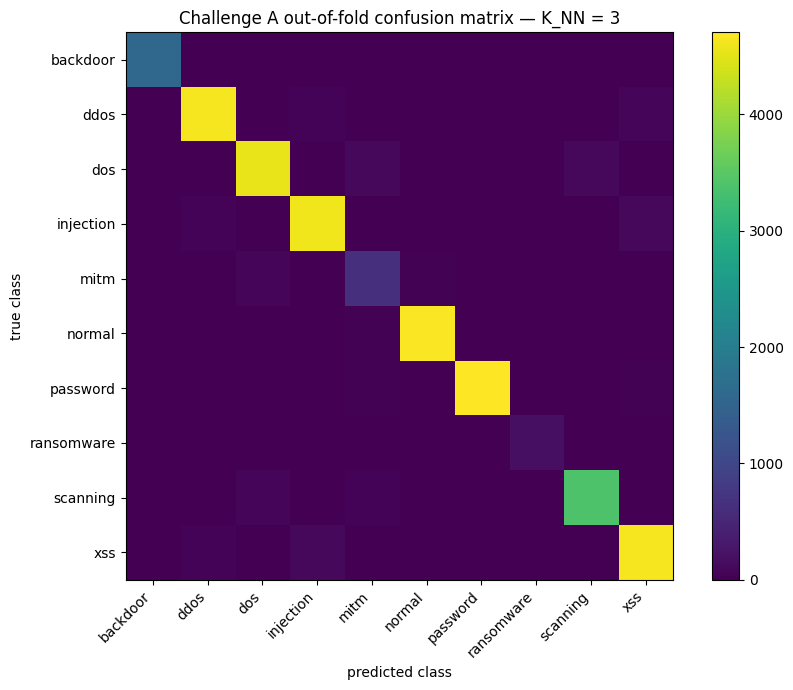

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(confusion)
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title(f"Challenge A out-of-fold confusion matrix — K_NN = {selected_neighbours}")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

### P2.4 interpretation

The KNN grid is reported in full rather than only at its maximum. On the canonical folds the best mean macro F1 is obtained at the selected `K_NN` printed above. The selected KNN is far above the most-frequent baseline on the primary metric and also on weighted F1 and accuracy.

The per-class table shows that `mitm` is the difficult class for this KNN representation: its F1 is much lower than the other classes. The confusion matrix shows that many `mitm` observations are confused especially with `dos`, `normal`, and `scanning`, while several of those classes also leak into `mitm`. This indicates overlap in the local feature-space neighbourhoods used by KNN. Ransomware is rare but its out-of-fold precision and recall remain high in the selected model; P2.5 examines that class probabilistically.

## P2.5 — Probabilistic evaluation and the rare ransomware class

We use the selected P2.4 KNN and the same canonical folds. The probabilities below are out-of-fold: each row is scored only by a model fitted without that row's canonical validation fold. Ransomware is then treated one-vs-rest for ROC/AUC and Brier evaluation.

In [15]:
y_ransomware = (y_cyber.to_numpy() == ransomware_code).astype(int)
ransomware_probability = oof_probability[:, ransomware_code]

fpr, tpr, roc_thresholds = roc_curve(y_ransomware, ransomware_probability, pos_label=1)
ransomware_auc = roc_auc_score(y_ransomware, ransomware_probability)
ransomware_brier = brier_score_loss(y_ransomware, ransomware_probability, pos_label=1)

print("Ransomware support:", int(y_ransomware.sum()))
print("Ransomware ROC AUC:", f"{ransomware_auc:.6f}")
print("Ransomware Brier score:", f"{ransomware_brier:.6f}")
print("Distinct ransomware probabilities:", sorted(np.unique(ransomware_probability)))

roc_table = pd.DataFrame({
    "threshold": roc_thresholds,
    "FPR": fpr,
    "TPR": tpr,
})
display(roc_table.round(6))

Ransomware support: 208
Ransomware ROC AUC: 0.978285
Ransomware Brier score: 0.000589
Distinct ransomware probabilities: [np.float64(0.0), np.float64(0.3333333333333333), np.float64(0.6666666666666666), np.float64(1.0)]


,threshold,FPR,TPR
0,inf,0.000000,0.000000
1,1.000000,0.000086,0.903846
2,0.666667,0.000288,0.942308
3,0.333333,0.001123,0.956731
4,0.000000,1.000000,1.000000


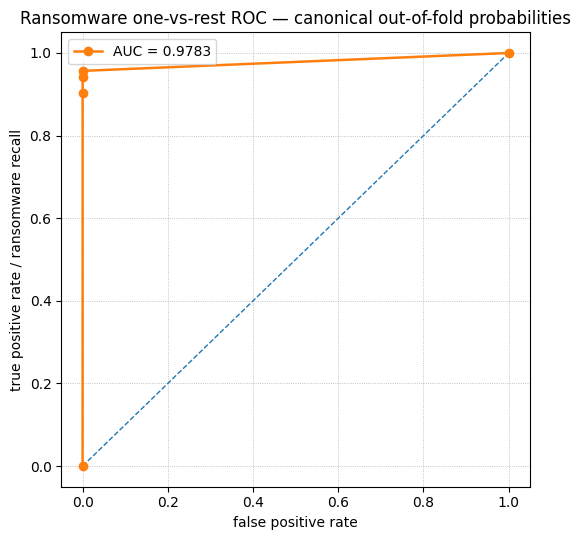

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.plot(fpr, tpr, marker="o", linewidth=1.8, label=f"AUC = {ransomware_auc:.4f}")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate / ransomware recall")
ax.set_title("Ransomware one-vs-rest ROC — canonical out-of-fold probabilities")
ax.legend()
ax.grid(linestyle=":", linewidth=0.6)
plt.tight_layout()
plt.show()

In [17]:
THRESHOLDS = [0.05, 0.10, 0.20, 0.35, 0.50]
other_class_codes = np.array([c for c in class_values if c != ransomware_code])

def ransomware_rule_metrics(prediction, rule_name):
    prediction = np.asarray(prediction)
    true_values = y_cyber.to_numpy()
    tp = int(((prediction == ransomware_code) & (true_values == ransomware_code)).sum())
    fp = int(((prediction == ransomware_code) & (true_values != ransomware_code)).sum())
    fn = int(((prediction != ransomware_code) & (true_values == ransomware_code)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    return {
        "rule": rule_name,
        "ransomware_support": int((true_values == ransomware_code).sum()),
        "ransomware_precision": precision,
        "ransomware_recall": recall,
        "false_alarms": fp,
        "macro_f1": f1_score(true_values, prediction, average="macro"),
        "predictions_changed_vs_argmax": int((prediction != oof_prediction).sum()),
        "changed_rows_whose_true_class_is_not_ransomware": int(
            ((prediction != oof_prediction) & (true_values != ransomware_code)).sum()
        ),
    }

threshold_rows = [ransomware_rule_metrics(oof_prediction, "ten-class argmax")]

for threshold in THRESHOLDS:
    force_ransomware = ransomware_probability >= threshold
    threshold_prediction = np.empty(n_rows, dtype=int)
    threshold_prediction[force_ransomware] = ransomware_code
    threshold_prediction[~force_ransomware] = other_class_codes[
        np.argmax(oof_probability[~force_ransomware][:, other_class_codes], axis=1)
    ]
    threshold_rows.append(
        ransomware_rule_metrics(threshold_prediction, f"tau={threshold:.2f}")
    )

threshold_report = pd.DataFrame(threshold_rows)
display(threshold_report.round(6))

,rule,ransomware_support,ransomware_precision,ransomware_recall,false_alarms,macro_f1,predictions_changed_vs_argmax,changed_rows_whose_true_class_is_not_ransomware
0,ten-class argmax,208,0.951456,0.942308,10,0.945517,0,0
1,tau=0.05,208,0.836134,0.956731,39,0.940066,32,29
2,tau=0.10,208,0.836134,0.956731,39,0.940066,32,29
3,tau=0.20,208,0.836134,0.956731,39,0.940066,32,29
4,tau=0.35,208,0.951456,0.942308,10,0.945517,0,0
5,tau=0.50,208,0.951456,0.942308,10,0.945517,0,0


### P2.5 interpretation

The ransomware support is small relative to the full development set, so the one-vs-rest diagnostics are reported beside that support. AUC describes ranking, while the Brier score evaluates the numerical probability errors; they answer different questions.

For this uniform-weight KNN the ransomware probability takes only a few discrete values because it is the fraction of the selected neighbours carrying the ransomware label. Consequently, several predeclared thresholds produce the same decisions. Lowering the threshold from the stricter regime increases ransomware recall, but it also increases false alarms and lowers ransomware precision. Each false alarm creates an additional case that an operator must triage. The table also reports how many predictions for rows whose true class is one of the other nine classes are changed, making the cost outside ransomware explicit. These thresholds are a fixed operational exercise only; none is used to retune the P2.4 model, whose primary selection metric remains macro F1.

## P2.6 — Submission-format dry run, OneR interpretation, and basis declaration

The dry run uses one canonical validation fold only as a temporary development subset. It has no special scoring status and is not carried forward as a pseudo-test set. The selected KNN is fitted on the other four folds, predictions are written with the exact final Cyber submission schema, and the supplied validator checks format only.

In [18]:
dry_fold_id = CANONICAL_FOLD_VALUES[0]
dry_valid_idx = np.flatnonzero(canonical_fold_id == dry_fold_id)
dry_train_idx = np.flatnonzero(canonical_fold_id != dry_fold_id)

dry_model = make_cyber_pipeline(selected_neighbours)
dry_model.fit(X_cyber.iloc[dry_train_idx], y_cyber.iloc[dry_train_idx])
dry_prediction = dry_model.predict(X_cyber.iloc[dry_valid_idx]).astype(int)

dry_features = cyber.iloc[dry_valid_idx][["row_id"] + MODEL_FEATURES].copy()
dry_submission = pd.DataFrame({
    "row_id": cyber.iloc[dry_valid_idx]["row_id"].to_numpy(),
    "attack_code": dry_prediction,
})

dry_features_file = OUTPUT_DIR / "cyber_dry_run_features.csv"
dry_submission_file = OUTPUT_DIR / "cyber_submission_dry_run.csv"
dry_features.to_csv(dry_features_file, index=False)
dry_submission.to_csv(dry_submission_file, index=False)

validator = subprocess.run(
    [
        sys.executable,
        str(VALIDATOR_FILE),
        "cyber",
        str(dry_submission_file),
        str(dry_features_file),
        str(CYBER_CLASS_CODES_FILE),
    ],
    capture_output=True,
    text=True,
)
print("Validator output:", validator.stdout.strip())
if validator.stderr.strip():
    print("Validator stderr:", validator.stderr.strip())
assert validator.returncode == 0
assert validator.stdout.strip() == "valid"
display(dry_submission.head())

Validator output: valid


,row_id,attack_code
0,C00001,9
1,C00004,1
2,C00017,5
3,C00020,2
4,C00022,6


### OneR interpretation

The simple OneR mechanism from Topic 6 cannot be inserted as a general baseline for this mixed-feature challenge without extra design decisions. A one-rule classifier requires a discrete set of values on the feature it uses. The nominal predictors already provide discrete categories, but the numeric predictors do not. To make OneR general across this table we would first have to choose a discretisation rule for numeric variables, including the number of bins and the bin boundaries. We would also have to decide how unseen or missing categories would be handled. Those choices would determine distinctions in the data on the model's behalf, so the Practice 2 baseline remains the course-specified `DummyClassifier(strategy="most_frequent")` rather than a custom OneR estimator.

### Frozen predictive-information basis — Challenge A

The primary Cyber basis is the eleven distributed source predictors: `proto`, `service`, `conn_state`, `duration`, `src_bytes`, `dst_bytes`, `missed_bytes`, `src_pkts`, `src_ip_bytes`, `dst_pkts`, and `dst_ip_bytes`. `row_id`, `feature_group`, and `fold_id` are never estimator inputs. The frozen representation declares `log1p` on the eight numeric predictors as a monotone representation transformation. Categorical encoding and method-required scaling are preprocessing choices that add no new predictive information.

In [19]:
# P2 comparison rows for Challenge A, in the course comparison-table schema.
def score_string(values):
    return " ".join(f"{value:.6f}" for value in values)

cyber_comparison_rows = pd.DataFrame([
    {
        "milestone": "P2",
        "challenge": "cyber",
        "family": "Dummy",
        "route": "primary",
        "configuration": "strategy=most_frequent",
        "preprocessing": "none (baseline ignores X)",
        "features": "features.md: 11 distributed source predictors (frozen basis)",
        "validation": "canonical StratifiedGroupKFold(5) on feature_group, read from cyber_folds.csv",
        "primary_metric_per_fold": score_string(dummy_metrics["macro_f1"]),
        "primary_metric": f"{dummy_metrics['macro_f1'].mean():.6f}",
        "primary_metric_spread": f"range={dummy_metrics['macro_f1'].max() - dummy_metrics['macro_f1'].min():.6f}",
        "supporting_metrics": f"mean weighted F1={dummy_metrics['weighted_f1'].mean():.6f}; mean accuracy={dummy_metrics['accuracy'].mean():.6f}",
        "fit_time_s": f"{dummy_metrics['fit_time_s'].sum():.6f} total CV fit time",
        "interpretability": "none",
        "notes": "Establishes the most-frequent-class baseline without reading predictor values.",
    },
    {
        "milestone": "P2",
        "challenge": "cyber",
        "family": "KNN",
        "route": "primary",
        "configuration": f"KNeighborsClassifier(n_neighbors={selected_neighbours})",
        "preprocessing": "one-hot nominal; log1p + StandardScaler numeric; fitted inside each fold",
        "features": "features.md: 11 distributed source predictors (frozen basis)",
        "validation": "canonical StratifiedGroupKFold(5) on feature_group, read from cyber_folds.csv",
        "primary_metric_per_fold": score_string(selected_metrics["macro_f1"]),
        "primary_metric": f"{selected_metrics['macro_f1'].mean():.6f}",
        "primary_metric_spread": f"range={selected_metrics['macro_f1'].max() - selected_metrics['macro_f1'].min():.6f}",
        "supporting_metrics": f"mean weighted F1={selected_metrics['weighted_f1'].mean():.6f}; mean accuracy={selected_metrics['accuracy'].mean():.6f}",
        "fit_time_s": f"{selected_metrics['fit_time_s'].sum():.6f} total CV fit time",
        "interpretability": "none",
        "notes": "Uses local neighbourhood structure and strongly improves on the most-frequent baseline.",
    },
])

display(cyber_comparison_rows)
cyber_comparison_rows.to_csv(OUTPUT_DIR / "comparativa_p2_cyber.csv", index=False)

,milestone,challenge,family,route,configuration,preprocessing,features,validation,primary_metric_per_fold,primary_metric,primary_metric_spread,supporting_metrics,fit_time_s,interpretability,notes
0,P2,cyber,Dummy,primary,strategy=most_frequent,none (baseline ignores X),features.md: 11 distributed source predictors ...,canonical StratifiedGroupKFold(5) on feature_g...,0.024163 0.024163 0.024166 0.024163 0.024166,0.024164,range=0.000003,mean weighted F1=0.033208; mean accuracy=0.137426,0.022614 total CV fit time,none,Establishes the most-frequent-class baseline w...
1,P2,cyber,KNN,primary,KNeighborsClassifier(n_neighbors=3),one-hot nominal; log1p + StandardScaler numeri...,features.md: 11 distributed source predictors ...,canonical StratifiedGroupKFold(5) on feature_g...,0.943582 0.947290 0.948997 0.942843 0.945072,0.945557,range=0.006154,mean weighted F1=0.962348; mean accuracy=0.962065,0.523545 total CV fit time,none,Uses local neighbourhood structure and strongl...


## Challenge A completion check

- P2.1 data contract and class/group exploration: complete.
- P2.2 own grouped construction, invariant, split-protocol comparison, freeze, canonical comparison and adoption: complete.
- P2.4 baseline, full KNN curve, selected model, full supporting metrics, confusion matrix and per-class report: complete.
- P2.5 ransomware probability, ROC/AUC, Brier and all fixed thresholds: complete.
- P2.6 Cyber dry run, validator check, OneR interpretation, basis declaration and comparison rows: complete.

P2.2(c) and P2.3 are Challenge B tasks and are therefore contained in the separate Storage notebook rather than duplicated here.